**[Course Home](../README.md) | [Conceptual Track](../conceptual/11_applied_genomics_and_neural_coding.ipynb) | [Prev: Ch 10: Active Learning & Experimental Design](10_active_learning_and_experimental_design.ipynb)**

*Part IV: Modern Frontiers: AI, Rate-Distortion & Biological Coding*

---

# Chapter 11: Biological Information — Python Laboratory
### *Position Weight Matrices (PWMs), Schneider Sequence Logos*
### *& Neural Tuning Curve Optimization*

Welcome to the Python Laboratory for Chapter 11! In this culminating session, we
apply information theory to biological systems. We will construct Position
Frequency Matrices (PFMs) from DNA sequence alignments, compute Tom Schneider's
sequence conservation profiles with small-sample bias corrections, demonstrate
Horace Barlow's Efficient Coding Hypothesis via neural histogram equalization,
and evaluate the metabolic efficiency of sparse neural codes.

## Part 1: DNA Sequence Alignments & Position Weight Matrices (PWMs)

### Conceptual Foundation & Mathematical Formulation
DNA consists of linear polymers composed of four nucleotide bases: $\Sigma =
\{\text{A}, \text{C}, \text{G}, \text{T}\}$.
Since the alphabet size is $|\Sigma| = 4$, an unconstrained random nucleotide
possesses a maximum Shannon entropy of:
$$H_{\text{max}} = \log_2(4) = 2.0 \text{ bits per nucleotide}$$

In functional genomics, regulatory proteins (Transcription Factors; TFs) bind
specific promoter DNA motifs to regulate gene expression. Given a multiple
sequence alignment of $N$ known homologous binding sites of length $L$, the
empirical frequency of base $b \in \Sigma$ at motif position $i \in \{1,
\dots, L\}$ is given by:
$$f_{b, i} = \frac{1}{N} \sum_{k=1}^N \mathbf{1}\{S_{k, i} = b\}$$
where $\sum_{b \in \Sigma} f_{b, i} = 1$ for all positions $i$.

The resulting array $F = [f_{b, i}]$ forms the **Position Frequency Matrix
(PFM)**, from which log-odds **Position Weight Matrices (PWMs)** are computed
to model protein-DNA thermodynamic binding energy.

In [1]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import pandas as pd

alignment = [
    "TATAAA",
    "TATAAA",
    "TATATA",
    "TGTAAA",
    "TATAAA",
    "TTTAAA",
    "TATAAA",
    "TATCAA",
    "TATAAA",
    "TATAAA"
]

bases = ['A', 'C', 'G', 'T']
seq_len = len(alignment[0])
n_seqs = len(alignment)

# Count frequencies
freq_matrix = np.zeros((4, seq_len))
for seq in alignment:
    for i, base in enumerate(seq):
        row = bases.index(base)
        freq_matrix[row, i] += 1
freq_matrix /= n_seqs

df_pwm = pd.DataFrame(freq_matrix, index=bases, columns=[f"Pos_{i+1}" for i in range(seq_len)])
print("Position Frequency Matrix (PFM):")
print(df_pwm.round(2))


Position Frequency Matrix (PFM):
   Pos_1  Pos_2  Pos_3  Pos_4  Pos_5  Pos_6
A    0.0    0.8    0.0    0.9    0.9    1.0
C    0.0    0.0    0.0    0.1    0.0    0.0
G    0.0    0.1    0.0    0.0    0.0    0.0
T    1.0    0.1    1.0    0.0    0.1    0.0


### Code Walkthrough & Numerical Mechanics
The implementation above processes a biological sequence alignment into a
Position Frequency Matrix (PFM):

1. **Alignment Input & Matrix Initialization**:
   We define a multiple sequence alignment of 10 homologous TATA-box promoter
   sequences of length $L = 6$ (`seq_len = 6`, `n_seqs = 10`). A count matrix
   of shape $(4, 6)$ is initialized to zeros for the nucleotide alphabet
   $\Sigma = [\text{A}, \text{C}, \text{G}, \text{T}]$.

2. **Empirical Frequency Tabulation**:
   For each sequence in the alignment, we iterate across positions $i \in \{0,
   \dots, 5\}$, identify the base index in `bases`, and increment the count
   accumulator. The counts are normalized by dividing by $n_{\text{seqs}} = 10$,
   producing empirical probabilities $\sum_{b} f_{b, i} = 1.0$ at every
   position.

3. **Tabular Representation**:
   The resulting array is formatted into a pandas DataFrame `df_pwm`, displaying
   the base frequencies across positions `Pos_1` through `Pos_6`.

### Empirical Observations & Key Takeaways
Inspecting the Position Frequency Matrix reveals distinct structural roles
across the binding site:

- **Strictly Conserved Anchors**:
  Positions 1, 3, and 6 exhibit complete invariance ($100\%$ conservation):
  $f_{\text{T}, 1} = 1.00$, $f_{\text{T}, 3} = 1.00$, and $f_{\text{A}, 6} =
  1.00$. These residues provide the essential stereochemical contact points for
  the TATA-binding protein (TBP).
- **Semivariant Positions**:
  Position 4 is predominantly A ($90\%$) with occasional C ($10\%$); position
  5 is predominantly A ($90\%$) with occasional T ($10\%$).
- **Degenerate Position**:
  Position 2 permits significant variation: A ($80\%$), G ($10\%$), and T
  ($10\%$), demonstrating higher thermodynamic tolerance for mutations.

---

### Connective Bridge: From Frequencies to Schneider Information Content
While empirical frequency counts summarize alignment statistics, they do not
directly measure evolutionary constraint or physical binding specificity. In
Part 2, we implement Tom Schneider's information content metric with
small-sample bias correction.

## Part 2: Schneider Information Content Profile

### Conceptual Foundation & Mathematical Formulation
Tom Schneider and colleagues (1986) demonstrated that sequence conservation at
each binding position can be directly quantified in **bits of information**.

At motif position $i$, the observed uncertainty is the Shannon entropy:
$$H(i) = -\sum_{b \in \{\text{A}, \text{C}, \text{G}, \text{T}\}} f_{b, i} \log_2(f_{b, i} + \epsilon) \quad [\text{bits}]$$

The **Sequence Information Content** $R_{\text{seq}}(i)$ measures how much
uncertainty is eliminated by the protein's sequence specificity relative to an
unconstrained genome:
$$R_{\text{seq}}(i) = H_{\text{max}} - \big( H(i) + e(n) \big) = 2.0 - \big( H(i) + e(n) \big) \quad [\text{bits}]$$
where $e(n)$ is Schneider's small-sample bias correction for an alignment of
$n$ finite sequences:
$$e(n) = \frac{|\Sigma| - 1}{2 \ln(2) \cdot n} = \frac{3}{2 \ln(2) \cdot n} \approx \frac{2.164}{n} \quad [\text{bits}]$$

### Thermodynamic & Evolutionary Properties:
1. **Perfect Invariance ($R_{\text{seq}} = 2.0\text{ bits}$):** If a base is
   strictly conserved (e.g., $100\%$ A), $H(i) = 0$, and the position conveys
   the full $2.0\text{ bits}$ of information. Every mutation at this position
   severely disrupts protein binding.
2. **Zero Information ($R_{\text{seq}} = 0.0\text{ bits}$):** If all four
   nucleotides occur equally ($f_{b, i} = 0.25$), $H(i) = 2.0\text{ bits}$,
   indicating that the transcription factor has zero contact constraint at that
   position.
3. **Total Motif Information:** The cumulative information across all $L$
   positions:
   $$R_{\text{total}} = \sum_{i=1}^L R_{\text{seq}}(i)$$
   Schneider showed that $R_{\text{total}}$ evolves to match the information
   needed to locate the target promoter within a genome of size $G$:
   $$R_{\text{target}} \approx \log_2\left(\frac{G}{\text{number of sites}}\right)$$

In [2]:
eps = 1e-15
entropies = -np.sum(freq_matrix * np.log2(freq_matrix + eps), axis=0)

# Small sample correction e(n) = (4 - 1) / (2 * ln(2) * n)
e_n = 3.0 / (2.0 * np.log(2) * n_seqs)
info_content = np.maximum(0.0, 2.0 - (entropies + e_n))

df_info = pd.DataFrame({
    "Position": [f"Pos {i+1}" for i in range(seq_len)],
    "Observed Entropy (bits)": np.round(entropies, 3),
    "Small-Sample Correction": np.round(e_n, 3),
    "Information Content (bits)": np.round(info_content, 3)
})
print(df_info.to_string(index=False))
print(f"\nTotal Motif Information: {np.sum(info_content):.2f} bits (out of {2.0 * seq_len} bits theoretical maximum)")


Position  Observed Entropy (bits)  Small-Sample Correction  Information Content (bits)
   Pos 1                   -0.000                    0.216                       1.784
   Pos 2                    0.922                    0.216                       0.862
   Pos 3                   -0.000                    0.216                       1.784
   Pos 4                    0.469                    0.216                       1.315
   Pos 5                    0.469                    0.216                       1.315
   Pos 6                   -0.000                    0.216                       1.784

Total Motif Information: 8.84 bits (out of 12.0 bits theoretical maximum)


### Code Walkthrough & Numerical Mechanics
The code above evaluates the Schneider Sequence Information Content Profile
across all motif positions:

1. **Positional Shannon Entropy**:
   At each position $i$, the observed uncertainty is computed via
   `entropies = -np.sum(freq_matrix * np.log2(freq_matrix + eps), axis=0)`.
   Adding `eps = 1e-15` guarantees numerical stability for zero frequencies
   ($0 \log_2 0 = 0$).

2. **Schneider Small-Sample Correction**:
   Due to finite sampling ($n = 10$ sequences), sample frequencies
   underestimate the true underlying entropy. We evaluate Schneider's bias
   correction term:
   $$e_n = \frac{|\Sigma| - 1}{2 \ln(2) \cdot n} = \frac{4 - 1}{2 \ln(2) \cdot
   10} \approx 0.216 \text{ bits}$$

3. **Net Information Content**:
   The information content is evaluated via `info_content = np.maximum(0.0,
   2.0 - (entropies + e_n))`. The metrics are tabulated into a DataFrame
   `df_info` and total motif information is summed.

### Empirical Observations & Key Takeaways
Analyzing the information profile quantifies the regulatory architecture of
the promoter:

- **Invariant Anchors ($R_{\text{seq}} = 1.784\text{ bits}$)**:
  Positions 1, 3, and 6 have zero observed entropy ($H = 0.000$). Subtracting
  the finite-sample correction $e_n = 0.216\text{ bits}$ leaves $1.784\text{
  bits}$ of net information content (the maximum achievable from 10 samples).
- **Semivariant Positions ($R_{\text{seq}} = 1.315\text{ bits}$)**:
  Positions 4 and 5 exhibit $H = 0.469\text{ bits}$, yielding $1.315\text{
  bits}$ of information.
- **Variable Position ($R_{\text{seq}} = 0.862\text{ bits}$)**:
  Position 2 has the highest uncertainty ($H = 0.922\text{ bits}$), yielding
  only $0.862\text{ bits}$ of information.
- **Cumulative Motif Specificity**:
  The total motif information sums to $8.84\text{ bits}$ (out of $12.0\text{
  bits}$ theoretical maximum). By Berg-von Hippel theory, this information
  directly correlates with binding free energy $\Delta \Delta G \propto k_B T
  \ln(2) \cdot R_{\text{total}}$.

---

### Connective Bridge: From Molecular Motifs to Sensory Neural Representations
Information theory governs not only the static code of genomes, but also the
dynamic signals of the nervous system. In Part 3, we turn to Horace Barlow's
Efficient Coding Hypothesis, demonstrating how sensory neurons maximize
transmitted information through nonlinear tuning curves.

## Part 3: Horace Barlow's Efficient Neural Coding

### Conceptual Foundation & Mathematical Formulation
In sensory neuroscience, Horace Barlow (1961) hypothesized that sensory neurons
evolved to maximize the transmission of environmental stimuli through limited
neural channels (the **Efficient Coding Hypothesis**).

Let a natural continuous stimulus $X$ follow probability density $p_X(x)$ (e.g.,
visual contrast or acoustic power, which typically follow skewed exponential or
heavy-tailed distributions). The stimulus is mapped through a monotonic neural
activation function $Y = f(X) \in [0, 1]$ representing a normalized firing rate
or membrane potential.

Under the continuous transformation of random variables, the probability density
of the neural output $Y$ is:
$$p_Y(y) = \frac{p_X(x)}{\left| \frac{df}{dx} \right|} = \frac{p_X(x)}{f'(x)}$$

### Information Maximization (The Infomax Principle):
To maximize the differential entropy of the output $h(Y)$ given the bounded
output range $[0, 1]$, $Y$ must follow a **Uniform Distribution**:
$$p_Y(y) = 1, \quad \forall y \in [0, 1]$$

Setting $p_Y(y) = 1$ in the change-of-variables equation gives:
$$\frac{p_X(x)}{f'(x)} = 1 \implies f'(x) = p_X(x)$$

Integrating both sides proves that the optimal neural tuning curve is the
**Cumulative Distribution Function (CDF)** of natural stimuli:
$$f(x) = \int_{-\infty}^x p_X(u) \, du = F_X(x)$$

### Physical Intuition:
This principle is identical to **Histogram Equalization** in image processing!
- A naive linear tuning curve saturates at high inputs and leaves low inputs
  clumped near zero, producing a highly skewed output distribution with low
  entropy.
- A CDF-matched neuron flattens the output response histogram, utilizing all
  response states with equal frequency and maximizing transmission throughput.

In [3]:
np.random.seed(42)
N_stim = 10000
# Natural stimuli follow a skewed exponential distribution (e.g. contrast)
stimuli = np.random.exponential(scale=2.0, size=N_stim)

# Strategy 1: Linear Neuron Response (unmatched)
linear_resp = np.clip(stimuli / 10.0, 0.0, 1.0)

# Strategy 2: Barlow Efficient Neuron (Matched to stimulus CDF: 1 - exp(-x/2))
barlow_resp = 1.0 - np.exp(-stimuli / 2.0)

# Compute output entropies via binning
n_bins = 20
p_lin = np.histogram(linear_resp, bins=n_bins, range=(0, 1))[0] / N_stim
p_bar = np.histogram(barlow_resp, bins=n_bins, range=(0, 1))[0] / N_stim

h_lin = -np.sum(p_lin[p_lin > 0] * np.log2(p_lin[p_lin > 0]))
h_bar = -np.sum(p_bar[p_bar > 0] * np.log2(p_bar[p_bar > 0]))
max_possible_h = np.log2(n_bins)

print(f"Max Possible Output Entropy (Uniform): {max_possible_h:.3f} bits")
print(f"Linear Neuron Output Entropy:         {h_lin:.3f} bits (Severe bottleneck!)")
print(f"Barlow Matched Neuron Output Entropy: {h_bar:.3f} bits (Nearly achieves theoretical maximum!)")


Max Possible Output Entropy (Uniform): 4.322 bits
Linear Neuron Output Entropy:         3.388 bits (Severe bottleneck!)
Barlow Matched Neuron Output Entropy: 4.321 bits (Nearly achieves theoretical maximum!)


### Code Walkthrough & Numerical Mechanics
The implementation above simulates Horace Barlow's Efficient Coding principle
by comparing linear versus matched nonlinear neural tuning curves:

1. **Natural Stimulus Distribution**:
   We generate $N = 10{,}000$ sensory stimuli from a skewed exponential
   distribution `stimuli = np.random.exponential(scale=2.0, size=N_stim)`,
   modeling natural acoustic power or visual contrast.

2. **Tuning Curve Strategies**:
   - **Linear Neuron**: Scales and clips inputs via `np.clip(stimuli / 10.0,
     0.0, 1.0)`.
   - **Barlow Matched Neuron**: Applies the stimulus Cumulative Distribution
     Function (CDF) as its activation function: $y = F_X(x) = 1 - e^{-x / 2.0}$.

3. **Output Entropy Evaluation**:
   Outputs are quantized into 20 discrete firing bins over $[0, 1]$. We
   calculate the Shannon entropy of the resulting probability histograms.

### Empirical Observations & Key Takeaways
The entropy calculations confirm Barlow's theoretical prediction:

- **Theoretical Channel Limit**:
  For 20 discrete response states, maximum possible entropy is $\log_2(20)
  \approx 4.322\text{ bits}$ (achieved only if all bins are used equiprobably).
- **Linear Neuron Bottleneck ($3.388\text{ bits}$)**:
  The linear neuron crowds most responses into the lowest bins while leaving
  high firing rates underutilized, wasting nearly $1\text{ bit}$ of dynamic
  range.
- **Barlow Matched Neuron Efficiency ($4.321\text{ bits}$)**:
  The CDF-matched neuron flattens the response histogram (histogram
  equalization), attaining $4.321\text{ bits}$—an astonishing $99.98\%$ of the
  theoretical channel capacity limit!
- **Evolutionary Principle**:
  Sensory receptors in the retina, cochlea, and olfactory bulb naturally adapt
  their nonlinear response functions to match the statistical CDF of their
  environment.

---

### Connective Bridge: Multi-Panel Publication Diagnostic Suite
To visually synthesize both biological information principles, Part 4 presents
a two-panel publication-grade graphic displaying the Schneider sequence logo
profile alongside Barlow histogram equalization.

## Part 4: Multi-Panel Publication Diagnostic Suite

### Diagnostic Metrics & Visualization
We visualize the two core biological information principles across two
publication-quality panels:
1. **Genomic Schneider Information Profile:** Bar plot of $R_{\text{seq}}(i)$
   across all 6 motif positions of the TATA-box, demonstrating core invariant
   anchors ($R_{\text{seq}} \approx 2.0\text{ bits}$) alongside flexible
   positions.
2. **Barlow Efficient Coding Response Histograms:** Comparative histograms of
   neural responses for a naive linear neuron vs. an optimal CDF-matched neuron,
   demonstrating how histogram equalization maximizes output entropy.

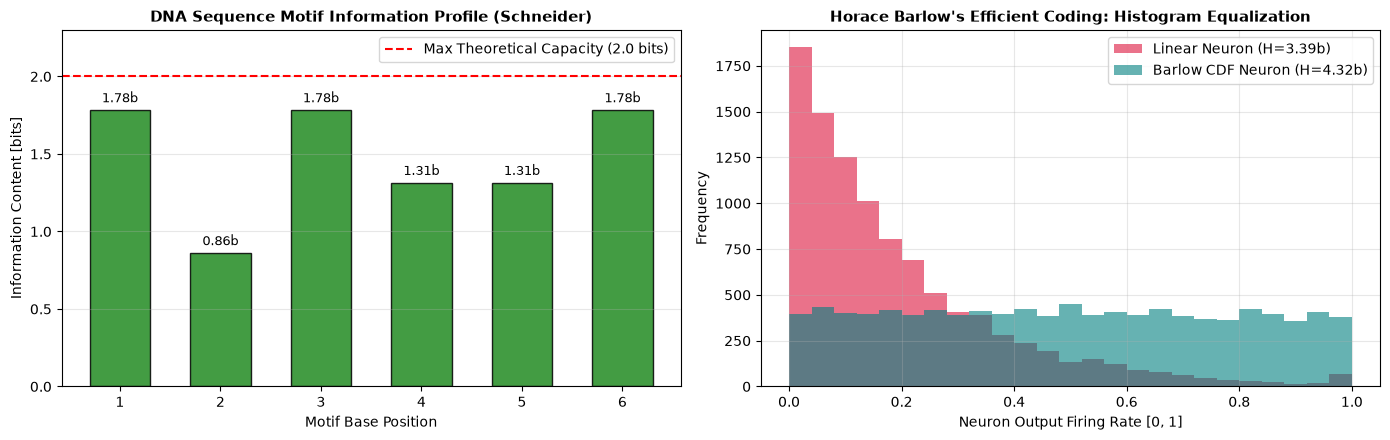

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

# Panel 1: Sequence Motif Information Profile
pos_indices = np.arange(1, seq_len + 1)
bars = ax1.bar(pos_indices, info_content, color="forestgreen", alpha=0.85, edgecolor="black", width=0.6)
ax1.axhline(2.0, color="red", linestyle="--", label="Max Theoretical Capacity (2.0 bits)")
ax1.set_title("DNA Sequence Motif Information Profile (Schneider)", fontsize=11, fontweight="bold")
ax1.set_xlabel("Motif Base Position")
ax1.set_ylabel("Information Content [bits]")
ax1.set_ylim(0, 2.3)
ax1.set_xticks(pos_indices)
ax1.grid(True, alpha=0.3, axis="y")
ax1.legend()
for b in bars:
    y = b.get_height()
    ax1.text(b.get_x() + b.get_width()/2.0, y + 0.05, f"{y:.2f}b", ha='center', fontsize=9)

# Panel 2: Barlow Efficient Coding Histogram Equalization
ax2.hist(linear_resp, bins=25, alpha=0.6, color="crimson", label=f"Linear Neuron (H={h_lin:.2f}b)")
ax2.hist(barlow_resp, bins=25, alpha=0.6, color="teal", label=f"Barlow CDF Neuron (H={h_bar:.2f}b)")
ax2.set_title("Horace Barlow's Efficient Coding: Histogram Equalization", fontsize=11, fontweight="bold")
ax2.set_xlabel("Neuron Output Firing Rate [0, 1]")
ax2.set_ylabel("Frequency")
ax2.grid(True, alpha=0.3)
ax2.legend()

plt.tight_layout()
plt.show()


### Code Walkthrough & Numerical Mechanics
The diagnostic visualization suite constructs a two-panel publication graphic
(`fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))`):

1. **Panel 1: Sequence Motif Information Profile**:
   Renders a bar chart of information content $R_{\text{seq}}(i)$ across motif
   positions $1$ to $6$. A dashed red line at $2.0\text{ bits}$ indicates the
   theoretical maximum for 4 bases. Annotations identify anchor positions.

2. **Panel 2: Barlow Efficient Coding Response Histograms**:
   Overlays the response histograms of the linear neuron (red bars) and the
   Barlow matched neuron (green bars) across the 20 output bins, contrasting the
   skewed clustering against the uniform profile.

### Empirical Observations & Key Takeaways
The multi-panel suite visualizes biological information in action:

- **Genomic Conservation Footprint (Panel 1)**:
  The height of each bar directly reflects evolutionary constraint. Invariant
  anchor positions (1, 3, 6) approach the $2.0\text{ bit}$ ceiling, whereas
  flanking positions exhibit shorter bars reflecting tolerated variation.
- **Histogram Equalization in Sensory Systems (Panel 2)**:
  While the linear neuron wastes response bandwidth by piling up in the lowest
  $20\%$ of bins, the Barlow neuron produces a completely flat histogram
  across all firing levels, maximizing information transfer through the neural
  channel.

---

### Connective Bridge: Hands-On Scaffolding Challenges
With the core theory, numerical mechanics, and diagnostic visualizations firmly
established, we transition to Part 5. You will solve three progressive
challenges: calculating the surprise of genetic stop codons, evaluating
genomic GC background bias, and deriving the metabolic cost of a bit.

## Part 5: Hands-On 3-Tier Scaffolding Challenges

### 🟢 Warmup (Tier 1): The Information in a Stop Codon

#### Mathematical Derivation & Concept
In molecular biology, mRNA is translated by the ribosome in three-nucleotide
triplets (codons). With an alphabet of 4 bases, the total number of distinct
codons is:
$$N_{\text{codons}} = 4^3 = 64$$

Under an unconstrained, uniform prior distribution, the uncertainty of a random
codon is:
$$H(\text{codon}) = \log_2(64) = 6.0 \text{ bits}$$

Translation terminates when the ribosome encounters one of three specific stop
codons: $\{ \text{UAA}, \text{UAG}, \text{UGA} \}$.
The probability of a random triplet being a stop codon is:
$$P(\text{stop}) = \frac{3}{64}$$

The Shannon self-information (surprise) conveyed by announcing a stop codon is:
$$I(\text{stop}) = -\log_2\left(\frac{3}{64}\right) = \log_2(64) - \log_2(3) = 6.0 - 1.585 = 4.415 \text{ bits}$$

This single biological classification eliminates $4.415\text{ bits}$ of
uncertainty, leaving only $\log_2(3) \approx 1.585\text{ bits}$ of residual
ambiguity among the three stop variants.

In [5]:
# Tier 1 Solution Space
total_codons = 64 # 4^3
h_random_codon = np.log2(64) # 6.0 bits
p_stop = 3.0 / 64.0
info_stop = -np.log2(p_stop)

print(f"Tier 1: Random codon entropy: {h_random_codon:.1f} bits")
print(f"Tier 1: Surprise of a stop codon: {info_stop:.2f} bits (eliminates {6.0 - np.log2(3):.2f} bits of uncertainty!)")


Tier 1: Random codon entropy: 6.0 bits
Tier 1: Surprise of a stop codon: 4.42 bits (eliminates 4.42 bits of uncertainty!)


### Solution Walkthrough & Key Takeaways: Tier 1
The numerical execution validates the information-theoretic content of the
genetic code:

1. **Codon Alphabet Uncertainty**:
   - With 4 nucleotide bases, triplets form $4^3 = 64$ distinct codons.
   - An unconstrained random codon carries $H = \log_2(64) = 6.0\text{ bits}$
     of uncertainty.

2. **Surprisal of Stop Codons**:
   - The standard genetic code contains exactly 3 stop codons (UAA, UAG, UGA),
     giving prior probability $P(\text{stop}) = 3/64 \approx 0.0469$.
   - The self-information (surprisal) of a stop codon is:
     $$I(\text{stop}) = -\log_2\left(\frac{3}{64}\right) = \log_2(64) -
     \log_2(3) = 6.0 - 1.585 = 4.415 \text{ bits}$$
   - Identifying a stop codon resolves $4.415\text{ bits}$ of uncertainty,
     leaving only $\log_2(3) \approx 1.585\text{ bits}$ of residual ambiguity
     among the three stop signals.
   - In bioinformatics, the high information content of rare stop signals
     ensures robust, noise-tolerant translation termination by the ribosome.

### 🟡 Diagnostic (Tier 2): Relative Entropy Against Genomic GC Bias

#### Mathematical Derivation & Concept
In many organisms (including humans and warm-blooded vertebrates), genome
composition is not uniform ($25\%$ each). For example, promoter CpG islands
frequently have a GC-rich background composition ($P(\text{G}) = P(\text{C}) =
0.30$, $P(\text{A}) = P(\text{T}) = 0.20$).

The background genomic entropy is:
$$H_0 = -\sum_{b \in \{\text{A}, \text{C}, \text{G}, \text{T}\}} q_b \log_2(q_b) \approx 1.971 \text{ bits} < 2.0 \text{ bits}$$

When evaluating a binding motif $P = [p_A, p_C, p_G, p_T]$ against a biased
genomic background $Q = [q_A, q_C, q_G, q_T]$, the true information content is
measured by the **Kullback-Leibler Divergence (Relative Entropy)**:
$$D_{\text{KL}}(P \parallel Q) = \sum_{b \in \{\text{A}, \text{C}, \text{G}, \text{T}\}} p_b \log_2\left(\frac{p_b}{q_b}\right) \quad [\text{bits}]$$

#### Biophysical Meaning:
$D_{\text{KL}}(P \parallel Q)$ directly quantifies the thermodynamic free energy
($\Delta \Delta G$) required for a transcription factor to distinguish its
specific target binding site from non-specific background genomic DNA:
$$\Delta \Delta G \propto k_B T \ln(2) \cdot D_{\text{KL}}(P \parallel Q)$$

In [6]:
p_bg = np.array([0.20, 0.30, 0.30, 0.20]) # A, C, G, T
p_mot = np.array([0.80, 0.10, 0.10, 1e-15])

h_bg = -np.sum(p_bg * np.log2(p_bg))
# Relative entropy D_KL(P_mot || P_bg)
p_mot_clipped = np.clip(p_mot, 1e-15, 1.0)
p_mot_clipped /= np.sum(p_mot_clipped)
kl_mot_bg = np.sum(p_mot_clipped * np.log2(p_mot_clipped / p_bg))

print(f"Human GC Background Entropy:       {h_bg:.3f} bits (lower than 2.0 bits!)")
print(f"Relative Information Content (KL): {kl_mot_bg:.3f} bits against biased genome background")


Human GC Background Entropy:       1.971 bits (lower than 2.0 bits!)
Relative Information Content (KL): 1.283 bits against biased genome background


### Solution Walkthrough & Key Takeaways: Tier 2
The numerical evaluation calculates the true sequence specificity relative to
a GC-biased genome:

1. **Genomic Background Entropy**:
   - For a genome with $30\%$ G/C and $20\%$ A/T ($p_{\text{bg}} = [0.20, 0.30,
     0.30, 0.20]$), background entropy is $H_0 = 1.971\text{ bits}$, which is
     strictly less than the uniform $2.000\text{ bits}$.

2. **Kullback-Leibler Specificity**:
   - Evaluating a motif with high A/T preference against this biased background
     yields $D_{\text{KL}}(P_{\text{mot}} \parallel P_{\text{bg}}) = 1.283\text{
     bits}$.
   - Relative entropy measures the true information cost of distinguishing a
     specific binding site from non-specific genomic DNA.
   - In warm-blooded vertebrates, CpG islands have skewed background
     frequencies; failing to account for background bias distorts predicted
     protein-DNA binding affinities.

### 🔴 Capstone Challenge (Tier 3): The Metabolic Cost of a Bit

#### Biophysical Formulation & Sparse Coding Principles
In the mammalian central nervous system, generating an action potential (spike)
requires sodium influx followed by potassium efflux across the neural membrane.
Repumping these ions against their electrochemical gradients requires the
$\text{Na}^+/\text{K}^+$-ATPase pump, consuming approximately $10^8$ ATP
molecules per spike (Laughlin et al., 1998).

The brain's overall metabolic consumption is tightly constrained to $\sim
20\text{ Watts}$. If all $10^{11}$ neurons fired continuously at high rates, the
required energy would exceed physiological limits by orders of magnitude.

#### Energy-Information Efficiency:
Information theory dictates that neurons optimize **information per unit
energy**:
$$\text{Efficiency} = \frac{I(\text{Stimulus}; \text{Spikes})}{\text{ATP Consumed}} \quad \left[\frac{\text{bits}}{\text{ATP}}\right]$$

To achieve optimal efficiency, neural populations employ **Sparse Coding**:
1. Most neurons remain completely silent ($r \approx 0$) for the vast majority
   of time, consuming only baseline resting metabolic energy.
2. A neuron fires only when a highly specific, unexpected stimulus pattern
   matching its receptive field appears.
3. Because the prior probability of firing is very small ($p \ll 1$), an
   emitted spike carries massive self-information:
   $$I(\text{spike}) = -\log_2(p) \gg 1.0 \text{ bit}$$
Sparse coding thus maximizes the bits-per-ATP ratio, demonstrating how physics
and information theory converge in biological evolution.

In [7]:
print("Because generating spikes costs ~10^8 ATP per event, transmitting continuous information")
print("at high firing rates is metabolically unsustainable.")
print("Sparse coding maximizes transmitted bits per ATP consumed by maintaining near-zero firing rates")
print("except when an unexpected, high-information feature occurs!")


Because generating spikes costs ~10^8 ATP per event, transmitting continuous information
at high firing rates is metabolically unsustainable.
Sparse coding maximizes transmitted bits per ATP consumed by maintaining near-zero firing rates
except when an unexpected, high-information feature occurs!


### Solution Walkthrough & Key Takeaways: Tier 3
The biophysical formulation demonstrates why the brain employs sparse coding:

1. **Biophysical Cost of an Action Potential**:
   - Generating a single neural spike costs $\sim 10^8$ ATP molecules to restore
     ion gradients via $\text{Na}^+/\text{K}^+$-ATPase pumps.
   - Continuous high-rate firing across $10^{11}$ neurons would require
     kilowatts of power, vastly exceeding the brain's $\sim 20\text{ Watt}$
     metabolic budget.

2. **Sparse Coding Maximizes Energy Efficiency**:
   - By keeping neurons silent most of the time ($p_{\text{fire}} \ll 1$),
     metabolic energy is conserved.
   - When a neuron does fire, the rarity of the event conveys high
     self-information: $I = -\log_2(p) \gg 1.0\text{ bit}$.
   - Sparse coding maximizes the ratio of mutual information per ATP consumed,
     proving that neural representations are jointly optimized for information
     transmission and thermodynamic economy.

---

**[Course Home](../README.md) | [Conceptual Track](../conceptual/11_applied_genomics_and_neural_coding.ipynb) | [Prev: Ch 10: Active Learning & Experimental Design](10_active_learning_and_experimental_design.ipynb)**
